In [110]:
pip install pandas numpy matplotlib seaborn scikit-learn #Imports


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#Imports': Expected package name at the start of dependency specifier
    #Imports
    ^


In [114]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

sns.set_style("whitegrid")


In [115]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target


In [116]:
X.head()
#print(X.isnull().sum().sum())  # Check for missing values
#print(X.shape[0]) # Number of rows

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [117]:
y.head()
#print(y.isnull().sum().sum())  # Check for missing values
#print(y.shape[0]) #Number of rows
print(y.value_counts()) # Check for class imbalance

target
1    357
0    212
Name: count, dtype: int64


Questions
Answer the following in a Markdown cell:

* How many observations are in the dataset?
* How many predictor variables are available?
* Are the features numerical or categorical?
* Are there any missing values?
* How many observations belong to each target class?
* Is the target balanced or imbalanced?

* 569
* 30
* They are numerical
* There are no missing values
* 569
* The target is imbalanced.

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


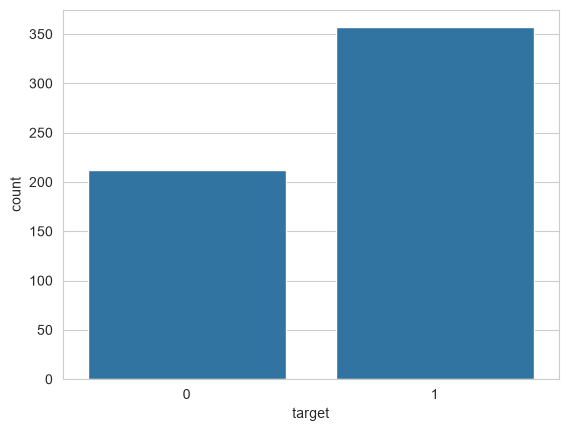

In [118]:
print(data.target_names)
print(y.value_counts())

pltbar = sns.countplot(x=y)

Questions
* What does class 0 represent?
* What does class 1 represent?
* Which class has more observations?
* Why should we consider class balance when evaluating a classification model?

* Class 0 is benign
* Class 1 is malignant
* Class 1 has 145 more observations compared to Class 0
* It is important to understand class balance when selecting for a classification model and to evaluate the results of the model.

In [119]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Training set size: {X_train.shape[0]}") # Uses shape to get the number of rows in the training set
print(f"Test set size: {X_test.shape[0]}") # Uses shape to get the number of rows in the test set
print(f"Features: {X_train.shape[1]}") # Uses shape to get the number of features
print(f'Unique Observations in training set: {X_train.index.nunique()}') # Uses nunique to get the number of unique classes in the training set

Training set size: 455
Test set size: 114
Features: 30
Unique Observations in training set: 455


Questions
Report:

* Number of training observations
* Number of test observations
* Number of features
* Explain why we use:
stratify=y

* 455
* 114
* 30
* Because there is a large gap in our testing feature, we want to ensure each set has positive and negative y's within, otherwise the model will become inaccurate if the training set has no positive y in it.

In [120]:
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)

#Generate predictions:

y_pred_tree = tree.predict(X_test)

#Calculate accuracy:

tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print("Accuracy:", tree_accuracy)

#Calculate F1:

tree_f1 = f1_score(
    y_test,
    y_pred_tree
)

print("F1:", tree_f1)

#Also display the classification report:

print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=data.target_names
    )
)

Accuracy: 0.9122807017543859
F1: 0.9285714285714286
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



Questions
* What accuracy did the decision tree achieve?
* What F1 score did it achieve?
* Why is it useful to establish a baseline before building an ensemble?
* What does it mean for a model to have high variance?

* .91 or 91% accurate for Accuracy
* .92 or 92% overall for F1
* Having a baseline helps us understand how the ensemble will preform compared to the baseline's results.
* A model with high variance can better predict outliar data points provided to it with increased accuracy.

In [121]:
observations = np.array([
    "A", "B", "C", "D", "E"
])

#Create a bootstrap sample:

bootstrap_sample = np.random.choice(
    observations,
    size=len(observations),
    replace=True
)


Questions
Observe the results and answer:

* Does every observation appear in every bootstrap sample?
* Can an observation appear more than once?
* Does each bootstrap sample contain five observations?
* What does replace=True mean?
* Why are the bootstrap samples different?

* No
* Yes
* Yes
* It means that each observation is taken individually of each other, allowing for duplicates
* Because each new sample is randomly selecting from the observation list, allowing duplicates

Written Explanation
In a Markdown cell, explain:

How does sampling with replacement allow us to create different training datasets from the same original dataset?

Replacement sampling will consistently generate random selections from the original dataset, without constraint on what it will include, only the sample size.

In [122]:
train_data = X_train.copy()

train_data["target"] = y_train.values

#Create a bootstrap sample:

bootstrap_sample = train_data.sample(
    n=len(train_data),
    replace=True,
    random_state=42
)

#Inspect:

print(bootstrap_sample.head())
print("Number of observations in bootstrap sample:", len(bootstrap_sample))

#Investigate the Sample
#Calculate the number of unique observations:

print(f'Number of unique observations in bootstrap sample: {bootstrap_sample.index.nunique()}')

#Compare this with:

print(f'Total number of observations in bootstrap sample: {len(bootstrap_sample)}')

     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
68         9.029         17.33           58.79      250.5          0.10660   
378       13.660         15.15           88.27      580.6          0.08268   
326       14.110         12.88           90.03      616.5          0.09309   
502       12.540         16.32           81.25      476.3          0.11580   
195       12.910         16.33           82.53      516.4          0.07941   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
68            0.14130         0.31300              0.04375         0.2111   
378           0.07548         0.04249              0.02471         0.1792   
326           0.05306         0.01765              0.02733         0.1373   
502           0.10850         0.05928              0.03279         0.1943   
195           0.05366         0.03873              0.02377         0.1829   

     mean fractal dimension  ...  worst texture  worst perimeter  wo

Questions
* Does the bootstrap sample have the same number of rows as the original training set?
* Does it have the same number of unique observations?
* Why are these numbers potentially different?
* What does this tell you about sampling with replacement?

* Yes, The training set had 455 observations as well
* No, The training set had 280 more unique observations.
* Because the bootstrap sampling can include duplicate samples
* Replacement sampling can produce samples that are identical to other samples.

In [123]:
bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

#Train the model:

bagging_tree.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


Create a comparison table:


Decision Tree|Accuracy	|  91%   |F1 score | 92%|
Bagging      |Accuracy  |  93%   |F1 score | 95%|

Questions
* Which model performed better?
* Did bagging improve accuracy?
* Did bagging improve F1?
* Was the improvement large or small?
* Why might combining multiple decision trees make predictions more stable?

* The Bagging model preformed margnally better, within a few percentiles for F1 and Accuracy
* Yes, by 2%
* Yes, by 3%
* It was a small improvement over Descision Tree modeling
* Mutilpe Descision Trees would be able to provide a voting system between the 5 trees where the majority perdiction is the decided prediction, decreasing the risk of perdiction error and increasing stability over just one Descision Tree's perdiction

Bagging combines predictions from multiple models.

Let's investigate how the number of models affects performance.

Train bagging classifiers using:

1
5
10
25
50
100

estimators.

For each value:

Create a BaggingClassifier.
Train it.
Generate predictions.
Calculate accuracy.
Calculate F1.
Store the results.
Create a DataFrame similar to:

Number of Estimators	Accuracy	F1
1	...	...
5	...	...
10	...	...
25	...	...
50	...	...
100	...	...
Visualization
Create a line plot showing accuracy against the number of estimators.

Then create another line plot showing F1 against the number of estimators.

Questions
What happens as the number of estimators increases?
Does performance improve indefinitely?
At what point does performance appear to become relatively stable?
What is the trade-off between using more estimators and computational cost?

              bagging_accuracy  bagging_f1
n_estimators                              
1                     0.921053    0.936170
5                     0.921053    0.937063
10                    0.929825    0.944444
25                    0.947368    0.958904
50                    0.938596    0.951724


<Axes: title={'center': 'Bagging Classifier Performance'}, xlabel='Number of Estimators', ylabel='F1 Score'>

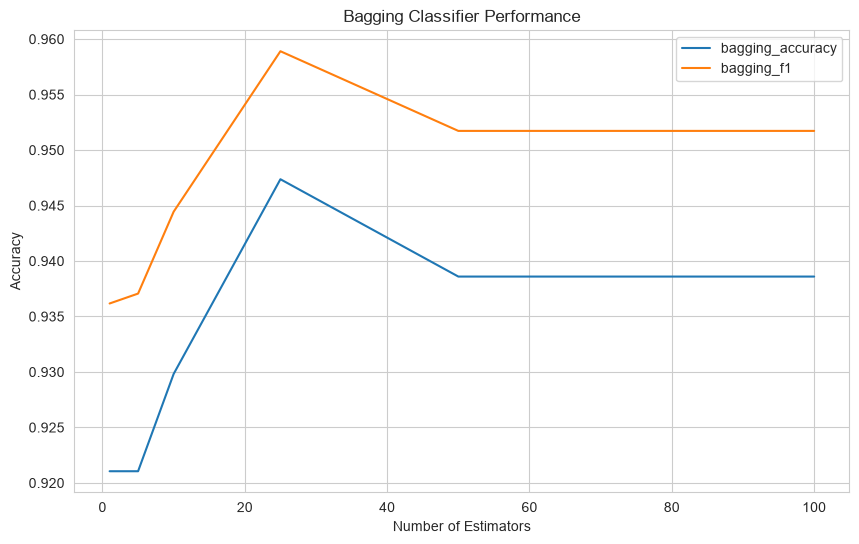

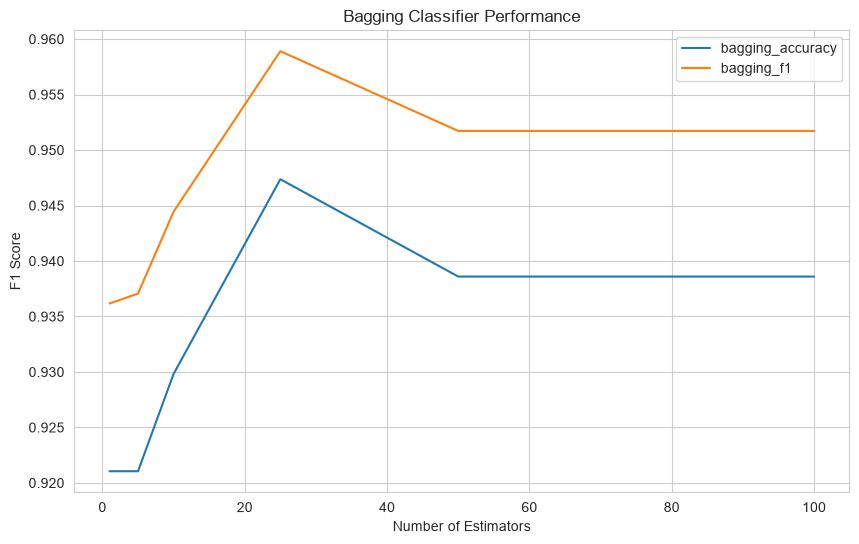

In [124]:
df = pd.DataFrame(columns=["bagging_accuracy", "bagging_f1"])
df.index.name = "n_estimators"
#####################################################################
bagging_tree01 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=1,
    random_state=42
)

#Train the model:

bagging_tree01.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree01.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[1] = [bagging_accuracy, bagging_f1]


####################################################################

bagging_tree05 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=5,
    random_state=42
)

#Train the model:

bagging_tree05.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree05.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[5] = [bagging_accuracy, bagging_f1]
####################################################################

bagging_tree10 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=10,
    random_state=42
)

#Train the model:

bagging_tree10.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree10.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[10] = [bagging_accuracy, bagging_f1]
####################################################################

bagging_tree25 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=25,
    random_state=42
)

#Train the model:

bagging_tree25.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree25.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[25] = [bagging_accuracy, bagging_f1]
####################################################################

bagging_tree50 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=50,
    random_state=42
)

#Train the model:

bagging_tree50.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree50.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[50] = [bagging_accuracy, bagging_f1]
####################################################################

bagging_tree100 = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

#Train the model:

bagging_tree100.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_bagging = bagging_tree100.predict(
    X_test
)

#Calculate accuracy and F1:

bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)


df.loc[100] = [bagging_accuracy, bagging_f1]

#####################################################################

print(df.head())

df.plot(
    kind="line",
    title="Bagging Classifier Performance",
    xlabel="Number of Estimators",
    ylabel="Accuracy",
    figsize=(10, 6)
)

df.plot(
    kind="line",
    title="Bagging Classifier Performance",
    xlabel="Number of Estimators",
    ylabel="F1 Score",
    figsize=(10, 6)
)

Questions
* What happens as the number of estimators increases?
* Does performance improve indefinitely?
* At what point does performance appear to become relatively stable?
* What is the trade-off between using more estimators and computational cost?

* The Esitmator's accuracy and R1 score peak at 25 and stabalize past esitmator 50.
* No, after a certain point, the estimator increasing hurts accuracy and R1 score and size becomes irrelevant past a certain estimator size
* Performance becomes perfectly stable past estimator 50.
* More estimators take more time and energy on the machine's end to run, therefore an estimator of 1 runs far faster than an estimator of 25, but one estimator preforms worse than 25.

In [125]:
compare_df = pd.DataFrame(
    columns=["Accuracy", "F1 Score"]
)
compare_df.index.name = "Model Name"

#Bagged Decision Tree
bag_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bag_tree.fit(  
    X_train,
    y_train
)

compare_df.loc["Bagged Decision Tree"] = [
    accuracy_score(y_test, bag_tree.predict(X_test)),
    f1_score(y_test, bag_tree.predict(X_test))
]

#Bagged Logistic Regression
bag_logistic = BaggingClassifier(
    estimator=LogisticRegression(
        max_iter=100000
    ),
    n_estimators=100,
    random_state=42
)

bag_logistic.fit(
    X_train,
    y_train
)

compare_df.loc["Bagged Logistic Regression"] = [
    accuracy_score(y_test, bag_logistic.predict(X_test)),
    f1_score(y_test, bag_logistic.predict(X_test))
]

#Bagged KNN
bag_knn = BaggingClassifier(
    estimator=KNeighborsClassifier(),
    n_estimators=100,
    random_state=42
)

bag_knn.fit(
    X_train,
    y_train
)
compare_df.loc["Bagged KNN"] = [
    accuracy_score(y_test, bag_knn.predict(X_test)),
    f1_score(y_test, bag_knn.predict(X_test))
]

compare_df.head()

,Accuracy,F1 Score
Model Name,,
Bagged Decision Tree,0.938596,0.951724
Bagged Logistic Regression,0.956140,0.965517
Bagged KNN,0.912281,0.929577


Questions
* Which base model performed best with bagging?
* Did bagging appear equally useful for all three models?
* Which model benefited most from the ensemble?
* Why might bagging be particularly useful for models with high variance?

* The Logistic Regression preformed the best
* Not equally useful, but still useful
* The Logistic Regression beneffited the most
* A model with high variance gains consistency through bagging, by comparing the results of the model several times.

In [126]:
#Create a Random Forest classifier:

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

#Train it:

rf.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_rf = rf.predict(
    X_test
)

#Calculate accuracy and F1:

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

print("Accuracy:", rf_accuracy)
print("F1:", rf_f1)

Accuracy: 0.956140350877193
F1: 0.9655172413793104


In [127]:
#Descision tree
#Bagged Decision Tree
#Random Forest

Tree_df = pd.DataFrame(
    columns=["Accuracy", "F1 Score"]
)   
Tree_df.index.name = "Model Name"

Tree_df.loc["Decision Tree"] = [
    accuracy_score(y_test, tree.predict(X_test)),
    f1_score(y_test, tree.predict(X_test))
]

Tree_df.loc["Bagged Decision Tree"] = [
    accuracy_score(y_test, bag_tree.predict(X_test)),
    f1_score(y_test, bag_tree.predict(X_test))
]

Tree_df.loc["Random Forest"] = [
    accuracy_score(y_test, rf.predict(X_test)),
    f1_score(y_test, rf.predict(X_test))
]

Tree_df.head()

,Accuracy,F1 Score
Model Name,,
Decision Tree,0.912281,0.928571
Bagged Decision Tree,0.938596,0.951724
Random Forest,0.956140,0.965517


Questions
Explain:

* What do Bagging and Random Forest have in common?
* What additional randomness does Random Forest introduce?
* How does random feature selection make the trees less correlated?
* Which model performed best?
* Why might reducing correlation between trees help the ensemble?

* Bagging and Random Forest both utilize bootstrap sampeling
* It will utilize a random subsect of features every split.
* Each tree is going to select random feautres, reducing the amount shared values between all trees
* Random Forest preformed the best overall in both Accuracy and F1
* Reduced coorelation can reduce bias among the model due to varied features among the trees

In [128]:
rf.feature_importances_

#Create a pandas Series:

importance_mdi = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print(importance_mdi)

#Check the total:

importance_mdi.sum()

#The values should sum to approximately 1.

worst area                 0.140016
worst concave points       0.129530
worst radius               0.097696
mean concave points        0.090885
worst perimeter            0.072226
mean perimeter             0.069574
mean radius                0.068676
mean concavity             0.057638
mean area                  0.049172
worst concavity            0.034340
area error                 0.033104
worst compactness          0.018600
worst texture              0.018597
radius error               0.016770
worst smoothness           0.012436
mean compactness           0.011715
perimeter error            0.009633
mean texture               0.009584
worst symmetry             0.008335
compactness error          0.005979
mean smoothness            0.005598
texture error              0.005214
worst fractal dimension    0.005166
mean symmetry              0.004666
mean fractal dimension     0.004489
fractal dimension error    0.004442
concavity error            0.004310
concave points error       0

np.float64(1.0)

* Which feature has the highest MDI importance?
* Which three features are most important?
* Which feature has the lowest importance?
* What does a high MDI importance indicate?
* What role do tree splits play in determining MDI importance?

* Worst area
* Worst area, worst concave points, and worst radius
* smoothness error
* A high MDI importance indicates more importance in the descision making
* Tree splits use the most useful features when determining a split

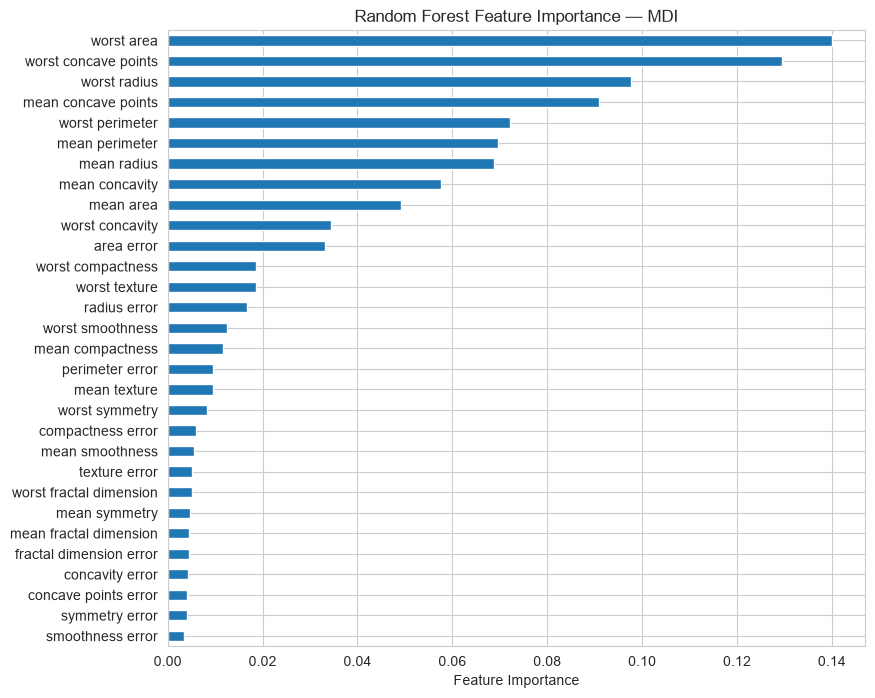

In [129]:
importance_mdi.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Feature Importance"
)

plt.title(
    "Random Forest Feature Importance — MDI"
)

plt.show()

Based on your visualization:

* Which features does the model rely on most?
* Are a few features responsible for a large proportion of the importance?
* Are there features with very small importance values?
* Does a low importance score necessarily mean the feature is useless?

* The top five are worst area, worst concave points, worst radius, mean concave points, and worst perimeter
* Yes, As they are porportionatley larger compared to other features
* Yes, with the smallest being .003499 and most being under .01
* It means the feature is useful, just not as impactful in determining a result.

Suppose your model reports:

worst radius → importance = 0.30

 * A student says:

"Worst radius is the most important feature, so worst radius causes a tumor to be malignant."

* Question
  Is this conclusion justified?

  Explain why or why not.

  Your answer should distinguish between:

  * Predictive usefulness
  * Association
  * Causation

While worst radius is an important factor in our descision tree, it does not nessecarily coorelate with malignant tumors, otherwise it should be a 1, rather than being a causation like the student claims, there is an association, a strong one at that, which will be beneficial for the desicion tree to use in predictions.

In [130]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

#Create a Series:

importance_permutation = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(
    ascending=False
)

print(importance_permutation)

compactness error          7.894737e-03
mean concave points        7.894737e-03
worst texture              7.017544e-03
worst area                 7.017544e-03
mean area                  5.263158e-03
mean smoothness            5.263158e-03
radius error               4.385965e-03
mean radius                4.385965e-03
concave points error       3.508772e-03
mean concavity             3.508772e-03
worst smoothness           2.631579e-03
worst concave points       2.631579e-03
mean fractal dimension     1.754386e-03
mean compactness           0.000000e+00
area error                 0.000000e+00
perimeter error            0.000000e+00
texture error              0.000000e+00
mean symmetry              0.000000e+00
mean perimeter             0.000000e+00
mean texture               0.000000e+00
concavity error            0.000000e+00
smoothness error           0.000000e+00
worst symmetry             0.000000e+00
fractal dimension error    0.000000e+00
symmetry error             0.000000e+00


Questions
* Which feature has the highest permutation importance?
* Which three features are most important?
* Are the results identical to the MDI results?
* Which features changed their ranking?
* Are any features close to zero?


* Compactness error at 7.89
* Compactness error, mean concave point, worst texture
* No, they are not the same
* Most features with a high MDI score have a low permutation importance and vice versa.
* mean compactness, area error, perimeter error, texture error, mean symmetry, mean perimeter, mean texture, concavity error, smoothness error, worst symmetry, fractal dimension error, symmetry error, and concavity error are all near 0.

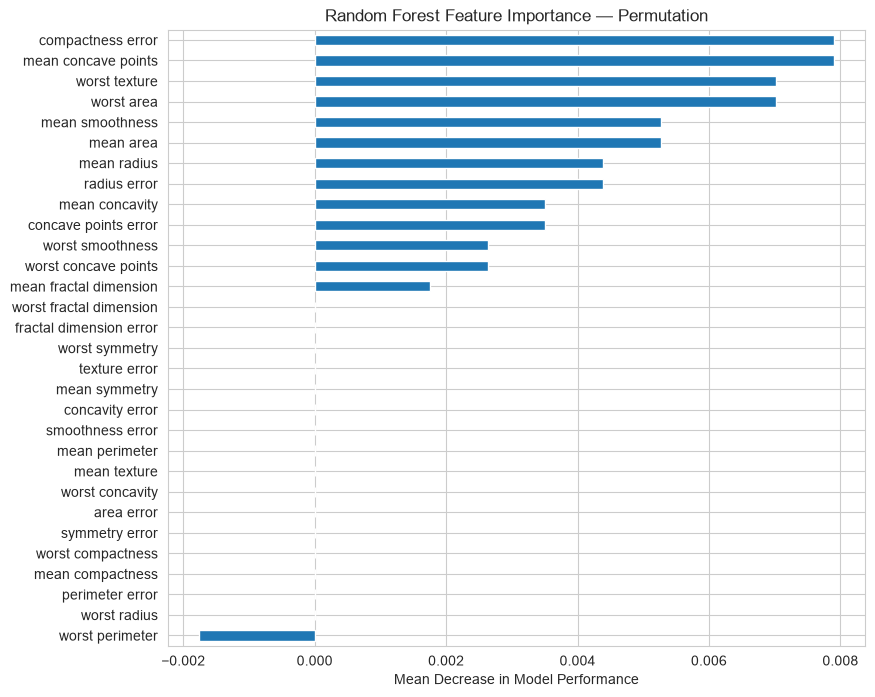

In [131]:
#Create a horizontal bar chart:

importance_permutation.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Mean Decrease in Model Performance"
)

plt.title(
    "Random Forest Feature Importance — Permutation"
)

plt.show()

* Which features have the largest performance impact when shuffled?
* Which features appear least important?
* How does this visualization compare with the MDI visualization?

* Compactness error, Mean concave points, and worst texture/worst area
* Every feature with a 0 mean decrease in model preformance is likely unimportant.
* A lot of the features scored with a high MDI were impacted the most by permutation.

In [132]:
importance_comparison = pd.DataFrame({
    "MDI": importance_mdi,
    "Permutation": importance_permutation
})

importance_comparison.sort_values(
    "MDI",
    ascending=False
)

,MDI,Permutation
worst area,0.140016,7.017544e-03
worst concave points,0.129530,2.631579e-03
worst radius,0.097696,-1.110223e-17
mean concave points,0.090885,7.894737e-03
worst perimeter,0.072226,-1.754386e-03
mean perimeter,0.069574,0.000000e+00
mean radius,0.068676,4.385965e-03
mean concavity,0.057638,3.508772e-03
mean area,0.049172,5.263158e-03
worst concavity,0.034340,0.000000e+00


* Which features are ranked highly by both methods?
* Which features have different rankings?
* Why might the two methods disagree?
* Which method directly measures the effect of a feature on model performance?
* Why might permutation importance take longer to calculate than MDI?

* Worst area, worst concave points, mean concave points, mean area.
* I would say most features have changed rankings depending on if you compare the MDI or Permutation charts to this combined one.
* Because Random feature importance can make irrelevant features more important then the relevant features, where MDI 
* MDI looks for the most impactful feature for model preformace whereas permutation takes a random feature.
* Permutation needs to calculate the original importance of the feature first before calculating it's permutation importance.
)

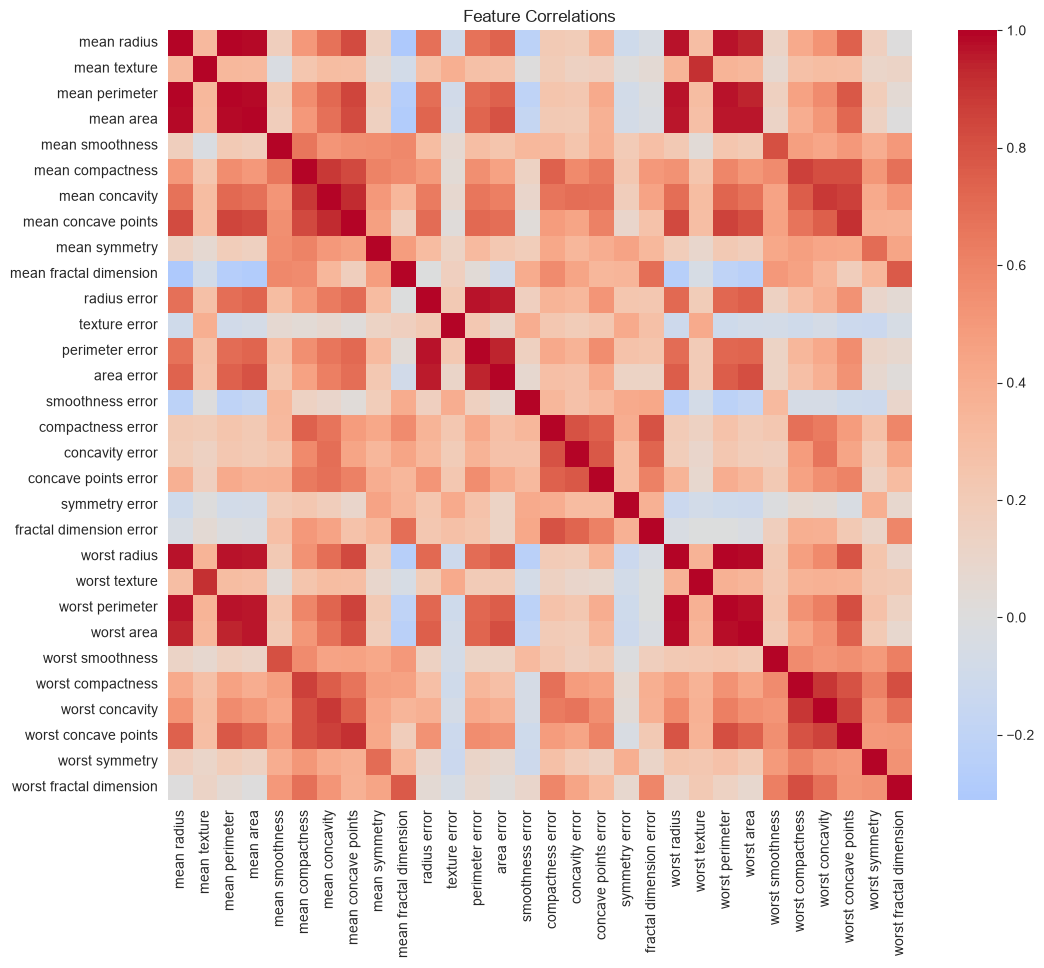

In [133]:
plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Feature Correlations"
)

plt.show()

#Identify at least one pair of strongly correlated features.
#Mean Radius and Mean Perimeter

Questions
* Which pair of features did you identify?
* Why can correlated features make feature importance difficult to interpret?
* If two features contain similar information, how might their importance be distributed?
* Could a feature have low importance even though it contains useful information?
* What does this tell you about interpreting feature importance?

* Radius error and Perimeter error
* Because if two features are correlated, then it becomes difficult to parse the individual impact of one or the other.
* Their importance is likely similarly valued if they contain similar information
* Yes, if that useful information is not impactful on the perdiction model.
* Feature importance is a balance between useful and impactful information.

In [134]:
voting_model = VotingClassifier(
    estimators=[
        (
            "tree",
            DecisionTreeClassifier(
                random_state=42
            )
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=100000
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ],
    voting="hard"
)

#Train the model:

voting_model.fit(
    X_train,
    y_train
)

#Generate predictions:

y_pred_voting = voting_model.predict(
    X_test
)

print("Accuracy:", accuracy_score(y_test, y_pred_voting))
print("F1:", f1_score(y_test, y_pred_voting))

Accuracy: 0.9473684210526315
F1: 0.9583333333333334


Questions
* How does hard voting make a prediction?
* How is voting different from bagging?
* Does the voting classifier outperform the individual models?
* Why might combining different types of models be useful?

* Hard voting makes a descion based on the majority result from the used models
* Bagging requires the same model type, while Hard voting can utilize various models in it's ensemble
* The voting classifier is able to take the output of three individual models and use those three outcomes to come to it's own conclusion, utilizing the strengths of three unique models at once.
* Being able to utilize different models to make a perdiction allows for more consistent perdictions.

Create one final DataFrame containing the major models built throughout the lab.

Include:

 * Decision Tree
 * Bagged Decision Tree
 * Bagged Logistic Regression
 * Bagged KNN
 * Random Forest
 * Voting Classifier
 The table should contain:

 Accuracy
 F1 score
For example:

Model	Accuracy	F1
Decision Tree	...	...
Bagged Decision Tree	...	...
Bagged Logistic Regression	...	...
Bagged KNN	...	...
Random Forest	...	...
Voting Classifier	...	...
Sort the table by F1 score from highest to lowest.

In [135]:
major_dataframe = pd.DataFrame(
    columns=["Accuracy", "F1 Score"]
)
major_dataframe.index.name = "Model Name"

major_dataframe = pd.concat([compare_df, Tree_df], axis=0)
major_dataframe.loc["Voting Classifier"] = [accuracy_score(y_test, y_pred_voting), f1_score(y_test, y_pred_voting)]
display(major_dataframe)


,Accuracy,F1 Score
Model Name,,
Bagged Decision Tree,0.938596,0.951724
Bagged Logistic Regression,0.956140,0.965517
Bagged KNN,0.912281,0.929577
Decision Tree,0.912281,0.928571
Bagged Decision Tree,0.938596,0.951724
Random Forest,0.956140,0.965517
Voting Classifier,0.947368,0.958333


* Bootstrapping
    * What is bootstrapping?
    * Why are observations repeated in a bootstrap sample?
    * Why might some observations be missing from a bootstrap sample?
    * Why does a bootstrap sample have the same number of observations as the original dataset?
* Bagging
    * What does bagging stand for?
    * How does bagging use bootstrap samples?
    * How does bagging combine model predictions?
    * Why can bagging reduce variance?
    * Why is bagging particularly useful for high-variance models?
* Random Forest
    * How does Random Forest extend bagging?
    * Why does Random Forest randomly select features?
    * Why is reducing the correlation between trees useful?
    * What is the difference between Bagging and Random Forest?
* Feature Importance
    * What does MDI measure?
    * What does permutation importance measure?
    * Why might MDI and permutation importance produce different rankings?
    * Why can correlated features complicate feature importance?
    * Why does feature importance not imply causation?
* Model Selection
    * Which model performed best in your experiment?
    * How did the best ensemble compare with the single decision tree?
    * Did increasing the number of estimators always improve performance?
    * Which base model benefited most from bagging?
    * What are the advantages of using an ensemble?
    * What are the disadvantages?
* If you were selecting a model for a real application, would you choose the model with the highest accuracy automatically? Explain.


* Bootstrapping
    * Bootstraping is taking a random sample from the dataframe
    * The samples taken from the dataframe are taken at complete random, not being splitted or having a block cut out.
    * Bootstrap samples can include repeated data, which will result in excluded data.
    * Bootstrapping takes samples until it has as many observations as there are total observations
* Bagging
    * Bootstrap aggregation
    * Bagging takes various bootstrap samples to train the models.
    * Either by the average of the perdictions for numerical values, or majority perdiction for classifcation
    * Bagging can reduce variance by providing mutiple models and their results being combined for one output
    * Having more perdictions to work with and to make a descision off of works to balance the high variance
* Random Forest
    * Random Forest considers random sampling among observations and features in making it's perdiction
    * Random Feature selection prevents repetitive descision trees, increasing variance.
    * Less corelation between trees reduces bias in the perdiction
    * Bagging only takes random observations, Random Forest takes random obeservations as well as random features
* Feature Importance
    * MDI measures the impact of the feature in reducing impurity
    * Permutation importance measures the impact of a feature on the training model
    * A feature that reduces impurity might not also be a feature that is relied upon by a feature
    * It can be difficult to tell the impact of a feature if it is highly correlated to another feature
    * Because a feature is highly important does not always mean that it is the cause
* Model Selection
    * Bagged Regression and Random Forest both had the highest F1 and Accuracy score
    * A single decision tree was worse than all ensembles, and Bagged Regression was better in comparison.
    * Not always, as past a certain point, in this case 50, the effects leveled out after decreasing from 25 estimators
    * Logistic Bagging benefited the most from bagging, likely because it handled numrical values over classification values.
    * Having an ensemble can increase the preformance of a model by having more perdictions that can help avoid outliar perdictions
    * It takes more computing power to process mutiple models, data assembly is put to random chance in bootstrapping

* No, as while a model with high accuracy may be great on paper, the intended application for the model matters more, and you would not select a model if it is not suited for the application, even if it has a great accuracy score.